## Norges Bank Currency Exchange Rates

This section retrieves EUR and USD exchange rates against NOK
from the Norges Bank open data API.

In [58]:
import pandas as pd
import requests
from io import StringIO



def download_nb_exchange_rates(
    currencies,
    start_date,
    end_date
):
    """
    Download daily exchange rates against NOK
    from the Norges Bank API.

    Parameters
    ----------
    currencies : list
        Currency codes, for example ["EUR", "USD"].
    start_date : str
        Start date in YYYY-MM-DD format.
    end_date : str
        End date in YYYY-MM-DD format.

    Returns
    -------
    pandas.DataFrame
        Daily exchange rates with one row per
        date and currency.
    """

    all_rates = []

    for currency in currencies:

        url = (
            "https://data.norges-bank.no/api/data/"
            f"EXR/B.{currency}.NOK.SP"
        )

        params = {
            "format": "csv",
            "startPeriod": start_date,
            "endPeriod": end_date,
            "locale": "en"
        }

        response = requests.get(
            url,
            params=params,
            timeout=30
        )

        response.raise_for_status()

        currency_df = pd.read_csv(
            StringIO(response.text),
            sep=";"
        )

        currency_df["currency"] = currency

        all_rates.append(
            currency_df
        )

    return pd.concat(
        all_rates,
        ignore_index=True
    )

In [59]:
exchange_rates = download_nb_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2024-01-01",
    end_date="2024-01-31"
)

exchange_rates.head()

,FREQ,Frequency,BASE_CUR,Base Currency,QUOTE_CUR,Quote Currency,TENOR,Tenor,DECIMALS,CALCULATED,UNIT_MULT,Unit Multiplier,COLLECTION,Collection Indicator,TIME_PERIOD,OBS_VALUE,currency
0,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-02,11.2815,EUR
1,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-03,11.3200,EUR
2,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-04,11.2845,EUR
3,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-05,11.3090,EUR
4,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-08,11.3620,EUR


## Timezone Investigation

This section compares the time conventions used by Magasinstatistikk,
ENTSO-E, Open-Meteo, and Norges Bank so that the datasets can be aligned
correctly before correlation and forecasting.

| Data source | Time information | Recommended handling |
|---|---|---|
| Magasinstatistikk | Weekly reservoir data is mainly date-based rather than hourly | Treat the observation date as the weekly reference date and align other data to the same weekly resolution |
| ENTSO-E | Electricity time series are handled with timezone-aware timestamps | Convert timestamps to UTC before combining with other hourly data |
| Open-Meteo | Default timezone is GMT/UTC unless another timezone is requested | Request UTC explicitly and keep weather timestamps timezone-aware |
| Norges Bank | Exchange rates are daily observations, normally published around 16:00 CET on business days | Treat the observation as a daily value and aggregate/join by date rather than exact publication time |

### Findings

The datasets do not all have the same temporal resolution. Open-Meteo and
ENTSO-E contain sub-daily observations, while Norges Bank provides daily
exchange rates and Magasinstatistikk provides weekly reservoir observations.

For this project, hourly weather and electricity timestamps will be converted
to UTC first. Before combining them with reservoir filling data, the higher-
frequency datasets will be aggregated to a common weekly resolution.

Norges Bank exchange rates will first be treated as daily observations and
then aggregated to the same weekly periods. This avoids incorrectly matching
the approximately 16:00 publication time with hourly observations.

Using one common timezone and one common time resolution before modelling
reduces the risk of shifted observations, especially around daylight-saving
time changes.

## Reservoir Filling Forecasting with River

This section develops an online machine-learning model for forecasting
future reservoir filling levels using lagged reservoir observations and
optional exogenous variables.

In [60]:
import numpy as np
import pandas as pd

from river import linear_model
from river import preprocessing
from river import metrics


def make_lag_features(series, lags=4):
    """
    Convert a time series into lag-based features.

    Parameters
    ----------
    series : pandas.Series
        Time-ordered reservoir filling values.
    lags : int
        Number of previous observations to use.

    Returns
    -------
    pandas.DataFrame
        Lagged feature table with target column.
    """

    df = pd.DataFrame({
        "target": series
    })

    for lag in range(1, lags + 1):
        df[f"lag_{lag}"] = df["target"].shift(lag)

    return df.dropna()

In [61]:
def river_reservoir_forecast(
    series,
    lags=4
):
    """
    Train and evaluate a River regression model
    using lagged reservoir filling values.
    """

    data = make_lag_features(
        series,
        lags=lags
    )

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    metric = metrics.MAE()

    predictions = []

    for timestamp, row in data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        y = row["target"]

        y_pred = model.predict_one(x)

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        if y_pred is not None:
            metric.update(y, y_pred)

        model.learn_one(x, y)

    result = pd.DataFrame(
        predictions
    ).set_index("date")

    return result, model, metric

In [62]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from nve_api import load_nve_data

In [63]:
reservoir_df = load_nve_data()

series = (
    reservoir_df[
        (reservoir_df["area_type"] == "EL")
        & (reservoir_df["area_number"] == 3)
    ]
    .sort_values("date")
    .set_index("date")["fill_level"]
    .dropna()
)

forecast_result, model, mae = river_reservoir_forecast(
    series,
    lags=8
)

print("MAE:", mae)
forecast_result.tail()

MAE: MAE: 0.040124


,actual,prediction
date,,
2026-10-11,0.725240,0.716153
2026-10-18,0.724940,0.727855
2026-10-25,0.717647,0.733813
2026-11-01,0.720149,0.728146
2026-11-08,0.718705,0.722519


In [64]:
%matplotlib inline

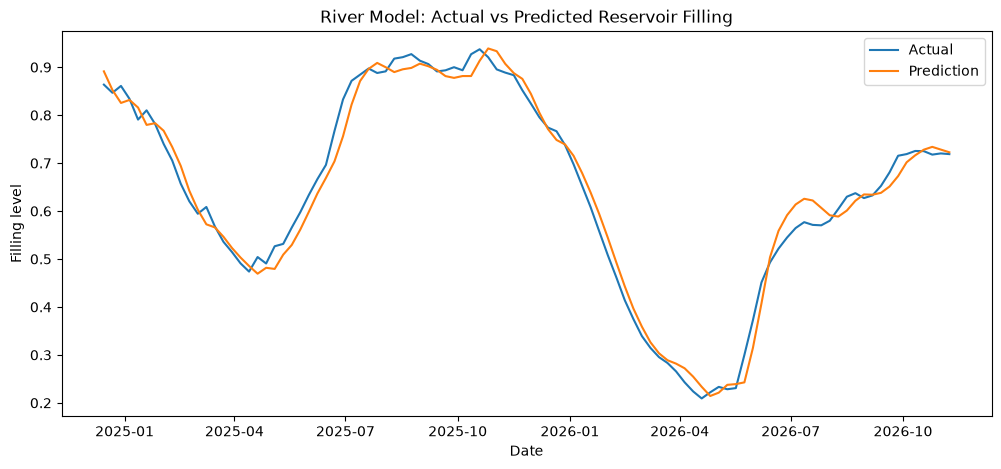

In [65]:
import matplotlib.pyplot as plt

plot_df = forecast_result.tail(100)

plt.figure(figsize=(12, 5))
plt.plot(
    plot_df.index,
    plot_df["actual"],
    label="Actual"
)
plt.plot(
    plot_df.index,
    plot_df["prediction"],
    label="Prediction"
)

plt.title("River Model: Actual vs Predicted Reservoir Filling")
plt.xlabel("Date")
plt.ylabel("Filling level")
plt.legend()
plt.show()

In [66]:
def forecast_future_weeks(
    model,
    history,
    lags=8,
    horizon=12
):
    """
    Forecast future reservoir filling values recursively.

    Parameters
    ----------
    model : River model
        Trained River regression model.
    history : pandas.Series
        Historical reservoir filling values.
    lags : int
        Number of lagged observations used by the model.
    horizon : int
        Number of future weeks to forecast.

    Returns
    -------
    pandas.Series
        Forecasted filling levels for future weeks.
    """

    history_values = list(history.dropna().values)

    future_predictions = []

    last_date = history.index.max()

    future_dates = pd.date_range(
        start=last_date + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="7D"
    )

    for future_date in future_dates:

        x = {
            f"lag_{lag}": history_values[-lag]
            for lag in range(1, lags + 1)
        }

        prediction = model.predict_one(x)

        # Keep filling level within valid range.
        prediction = max(0, min(1, prediction))

        future_predictions.append(prediction)

        # Recursive forecast:
        # use the prediction as part of the next step's history.
        history_values.append(prediction)

    return pd.Series(
        future_predictions,
        index=future_dates,
        name="forecast"
    )

In [67]:
future_forecast = forecast_future_weeks(
    model=model,
    history=series,
    lags=8,
    horizon=12
)

future_forecast

2026-11-15    0.714883
2026-11-22    0.706354
2026-11-29    0.698809
2026-12-06    0.689921
2026-12-13    0.681052
2026-12-20    0.672193
2026-12-27    0.661804
2027-01-03    0.651193
2027-01-10    0.640566
2027-01-17    0.630337
2027-01-24    0.620149
2027-01-31    0.610279
Freq: 7D, Name: forecast, dtype: float64

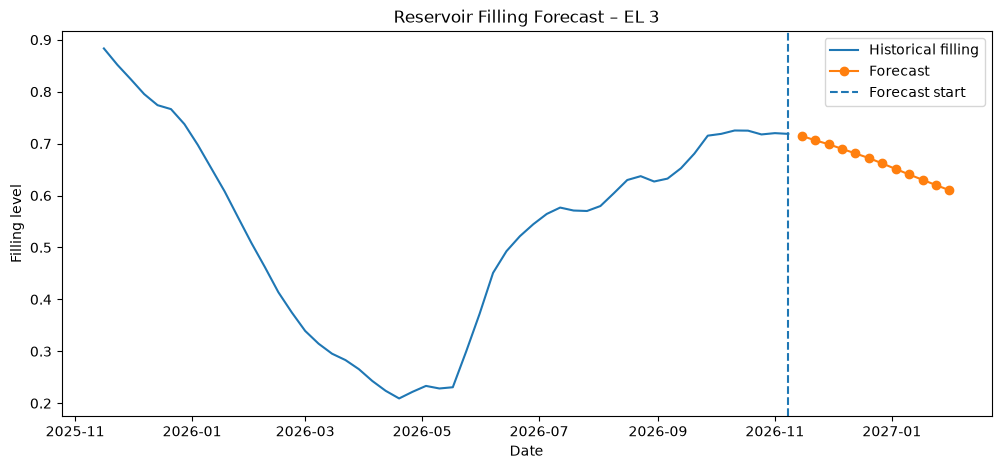

In [68]:
history_plot = series.tail(52)

plt.figure(figsize=(12, 5))

plt.plot(
    history_plot.index,
    history_plot,
    label="Historical filling"
)

plt.plot(
    future_forecast.index,
    future_forecast,
    marker="o",
    label="Forecast"
)

plt.axvline(
    series.index.max(),
    linestyle="--",
    label="Forecast start"
)

plt.title("Reservoir Filling Forecast – EL 3")
plt.xlabel("Date")
plt.ylabel("Filling level")
plt.legend()
plt.show()

In [69]:
def run_reservoir_forecast(
    reservoir_df,
    area_type="EL",
    area_number=3,
    history_weeks=260,
    lags=8,
    horizon=12
):
    """
    Train a River model and forecast reservoir filling.

    Parameters
    ----------
    reservoir_df : pandas.DataFrame
        Reservoir data from Magasinstatistikk.
    area_type : str
        Area type, for example "EL", "NO", or "VASS".
    area_number : int
        Selected area number.
    history_weeks : int
        Number of historical weeks used for training.
    lags : int
        Number of lag features.
    horizon : int
        Number of future weeks to forecast.

    Returns
    -------
    historical_predictions : pandas.DataFrame
    future_forecast : pandas.Series
    mae : River MAE metric
    """

    series = (
        reservoir_df[
            (reservoir_df["area_type"] == area_type)
            & (reservoir_df["area_number"] == area_number)
        ]
        .sort_values("date")
        .set_index("date")["fill_level"]
        .dropna()
    )

    # Limit training data to selected history length.
    if history_weeks is not None:
        series = series.tail(history_weeks)

    historical_predictions, model, mae = river_reservoir_forecast(
        series,
        lags=lags
    )

    future_forecast = forecast_future_weeks(
        model=model,
        history=series,
        lags=lags,
        horizon=horizon
    )

    return historical_predictions, future_forecast, mae

In [70]:
historical_predictions, future_forecast, mae = run_reservoir_forecast(
    reservoir_df=reservoir_df,
    area_type="EL",
    area_number=3,
    history_weeks=260,
    lags=8,
    horizon=12
)

print("MAE:", mae)
future_forecast

MAE: MAE: 0.122155


2026-11-15    0.666269
2026-11-22    0.636585
2026-11-29    0.607339
2026-12-06    0.573878
2026-12-13    0.539154
2026-12-20    0.504248
2026-12-27    0.467706
2027-01-03    0.435723
2027-01-10    0.413121
2027-01-17    0.390370
2027-01-24    0.371504
2027-01-31    0.357774
Freq: 7D, Name: forecast, dtype: float64

In [71]:
settings = [
    {"history_weeks": 104, "lags": 4},
    {"history_weeks": 156, "lags": 8},
    {"history_weeks": 260, "lags": 8},
    {"history_weeks": 260, "lags": 12},
]

results = []

for setting in settings:

    _, _, metric = run_reservoir_forecast(
        reservoir_df=reservoir_df,
        area_type="EL",
        area_number=3,
        history_weeks=setting["history_weeks"],
        lags=setting["lags"],
        horizon=12
    )

    results.append({
        "history_weeks": setting["history_weeks"],
        "lags": setting["lags"],
        "MAE": metric.get()
    })

comparison_df = pd.DataFrame(results)

comparison_df.sort_values("MAE")

,history_weeks,lags,MAE
2,260,8,0.122155
3,260,12,0.125069
1,156,8,0.173863
0,104,4,0.276706


In [72]:
def evaluate_river_model(
    series,
    history_weeks=260,
    lags=8,
    test_weeks=52
):
    """
    Train on historical data and evaluate on the same
    fixed test period for fair model comparison.
    """

    series = series.dropna().sort_index()

    # Fixed test period
    test_series = series.tail(test_weeks)

    # Training data immediately before test period
    train_series = series.iloc[:-test_weeks].tail(history_weeks)

    # Combine enough data to create lag features
    combined = pd.concat([
        train_series,
        test_series
    ])

    data = make_lag_features(
        combined,
        lags=lags
    )

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    # Train only on training dates
    for timestamp, row in data.iterrows():

        if timestamp >= test_series.index.min():
            break

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        model.learn_one(
            x,
            row["target"]
        )

    metric = metrics.MAE()
    predictions = []

    # Evaluate all settings on exactly the same test period
    for timestamp, row in data.loc[test_series.index.min():].iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        y = row["target"]
        y_pred = model.predict_one(x)

        metric.update(y, y_pred)

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        # River can continue learning sequentially
        model.learn_one(x, y)

    return (
        pd.DataFrame(predictions).set_index("date"),
        metric.get()
    )

In [73]:
settings = [
    {"history_weeks": 104, "lags": 4},
    {"history_weeks": 156, "lags": 8},
    {"history_weeks": 260, "lags": 8},
    {"history_weeks": 260, "lags": 12},
]

results = []

for setting in settings:

    _, mae_value = evaluate_river_model(
        series=series,
        history_weeks=setting["history_weeks"],
        lags=setting["lags"],
        test_weeks=52
    )

    results.append({
        "history_weeks": setting["history_weeks"],
        "lags": setting["lags"],
        "MAE": mae_value
    })

comparison_df = pd.DataFrame(results)

comparison_df.sort_values("MAE")

,history_weeks,lags,MAE
2,260,8,0.029078
3,260,12,0.032418
1,156,8,0.092303
0,104,4,0.163095


### Model comparison

The River model was tested using a fixed 52-week evaluation period so that
different history lengths and lag settings could be compared fairly.

Among the tested configurations, using 260 weeks of training history and
8 lagged filling observations performed best, with an MAE of approximately
0.029. Increasing the number of lags from 8 to 12 did not improve the result,
while shorter training histories produced noticeably larger errors.

Therefore, 260 weeks of history and 8 lags are used as the default settings
for the forecasting interface.

In [74]:
weather_df = pd.read_parquet(
    project_root / "data/no3_hourly_summary.parquet"
)

weather_df.head()

,time,precipitation,temperature_2m
0,2024-01-01 00:00:00,0.0061,-6.0299
1,2024-01-01 01:00:00,0.0051,-6.1797
2,2024-01-01 02:00:00,0.0051,-6.1304
3,2024-01-01 03:00:00,0.0051,-6.1585
4,2024-01-01 04:00:00,0.0051,-6.0807


In [75]:
weather_df["time"] = pd.to_datetime(weather_df["time"])

weekly_weather = (
    weather_df
    .set_index("time")
    .resample("W-SUN")
    .agg({
        "temperature_2m": "mean",
        "precipitation": "sum"
    })
    .rename(columns={
        "temperature_2m": "temperature_mean",
        "precipitation": "precipitation_sum"
    })
)

weekly_weather.head()

,temperature_mean,precipitation_sum
time,,
2024-01-07,-12.002976,1.4975
2024-01-14,-0.876277,55.9764
2024-01-21,-10.664716,10.3206
2024-01-28,0.469845,62.4742
2024-02-04,-1.357301,86.5746


In [76]:
forecast_data = (
    series.rename("fill_level")
    .to_frame()
    .join(
        weekly_weather,
        how="left"
    )
)

forecast_data.head()

,fill_level,temperature_mean,precipitation_sum
date,,,
1995-01-08,0.602376,NaN,NaN
1995-01-15,0.569943,NaN,NaN
1995-01-22,0.542203,NaN,NaN
1995-01-29,0.508148,NaN,NaN
1995-02-05,0.473883,NaN,NaN


In [77]:
forecast_2024 = forecast_data.loc[
    "2024-01-01":"2024-12-31"
].copy()

display(forecast_2024.head(10))

print("\nMissing values:")
print(forecast_2024.isna().sum())

print("\nNumber of weeks:")
print(len(forecast_2024))

,fill_level,temperature_mean,precipitation_sum
date,,,
2024-01-07,0.497182,-12.002976,1.4975
2024-01-14,0.476007,-0.876277,55.9764
2024-01-21,0.441178,-10.664716,10.3206
2024-01-28,0.428328,0.469845,62.4742
2024-02-04,0.423203,-1.357301,86.5746
2024-02-11,0.386791,-10.913034,6.4853
2024-02-18,0.353092,-4.176825,16.8449
2024-02-25,0.326199,-0.261936,22.7034
2024-03-03,0.301076,1.201788,14.0618



Missing values:
fill_level           0
temperature_mean     0
precipitation_sum    0
dtype: int64

Number of weeks:
52


In [78]:
def evaluate_river_with_weather(
    forecast_data,
    lags=8,
    test_weeks=12
):
    """
    Evaluate a River model using:
    - lagged reservoir filling
    - weekly mean temperature
    - weekly precipitation
    """

    data = forecast_data.dropna().copy()

    # Add lagged filling features
    for lag in range(1, lags + 1):
        data[f"lag_{lag}"] = data["fill_level"].shift(lag)

    data = data.dropna()

    test_data = data.tail(test_weeks)
    train_data = data.iloc[:-test_weeks]

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    # Train
    for _, row in train_data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        x["temperature_mean"] = row["temperature_mean"]
        x["precipitation_sum"] = row["precipitation_sum"]

        model.learn_one(
            x,
            row["fill_level"]
        )

    metric = metrics.MAE()
    predictions = []

    # Test sequentially
    for timestamp, row in test_data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        x["temperature_mean"] = row["temperature_mean"]
        x["precipitation_sum"] = row["precipitation_sum"]

        y = row["fill_level"]
        y_pred = model.predict_one(x)

        metric.update(y, y_pred)

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        model.learn_one(x, y)

    return (
        pd.DataFrame(predictions).set_index("date"),
        metric.get()
    )

In [79]:
weather_predictions, weather_mae = evaluate_river_with_weather(
    forecast_data=forecast_2024,
    lags=8,
    test_weeks=12
)

print("Weather model MAE:", weather_mae)

weather_predictions

Weather model MAE: 0.0697542573584376


,actual,prediction
date,,
2024-10-13,0.865961,0.792205
2024-10-20,0.870708,0.784460
2024-10-27,0.905651,0.968858
2024-11-03,0.923453,0.966749
2024-11-10,0.933162,0.739459
2024-11-17,0.940414,0.951942
2024-11-24,0.918573,0.724785
2024-12-01,0.906986,0.927817
2024-12-08,0.893050,0.816728


In [80]:
def evaluate_river_lag_only(
    forecast_data,
    lags=8,
    test_weeks=12
):
    """
    Evaluate a River model using only lagged
    reservoir filling values.
    """

    data = forecast_data[["fill_level"]].copy()

    for lag in range(1, lags + 1):
        data[f"lag_{lag}"] = data["fill_level"].shift(lag)

    data = data.dropna()

    test_data = data.tail(test_weeks)
    train_data = data.iloc[:-test_weeks]

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    # Train
    for _, row in train_data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        model.learn_one(
            x,
            row["fill_level"]
        )

    metric = metrics.MAE()
    predictions = []

    # Test
    for timestamp, row in test_data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        y = row["fill_level"]
        y_pred = model.predict_one(x)

        metric.update(y, y_pred)

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        model.learn_one(x, y)

    return (
        pd.DataFrame(predictions).set_index("date"),
        metric.get()
    )

In [81]:
lag_predictions, lag_mae = evaluate_river_lag_only(
    forecast_data=forecast_2024,
    lags=8,
    test_weeks=12
)

print("Lag-only MAE:", lag_mae)
print("Weather model MAE:", weather_mae)

Lag-only MAE: 0.03579384129696761
Weather model MAE: 0.0697542573584376


### Effect of weather variables

To test whether weather improved the forecast, I compared two River models
using the same 2024 data, 8 lag features, and the same 12-week test period.

The lag-only model achieved an MAE of approximately 0.036, while the model
including weekly mean temperature and precipitation had an MAE of approximately
0.070.

For this test period, adding weather variables reduced predictive performance.
One likely reason is that only one year of aligned weather data was available,
which provides a relatively small training sample after creating lag features.

Therefore, the lag-only model remains the better default for the current
implementation. Weather variables are kept as optional exogenous inputs so
their effect can be explored when longer historical weather series are available.

In [82]:
currency_df = download_nb_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2024-01-01",
    end_date="2024-12-31"
)

currency_df.head()

,FREQ,Frequency,BASE_CUR,Base Currency,QUOTE_CUR,Quote Currency,TENOR,Tenor,DECIMALS,CALCULATED,UNIT_MULT,Unit Multiplier,COLLECTION,Collection Indicator,TIME_PERIOD,OBS_VALUE,currency
0,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-02,11.2815,EUR
1,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-03,11.3200,EUR
2,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-04,11.2845,EUR
3,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-05,11.3090,EUR
4,B,Business,EUR,Euro,NOK,Norwegian krone,SP,Spot,4,False,0,Units,C,ECB concertation time 14:15 CET,2024-01-08,11.3620,EUR


In [83]:
currency_df.columns

Index(['FREQ', 'Frequency', 'BASE_CUR', 'Base Currency', 'QUOTE_CUR',
       'Quote Currency', 'TENOR', 'Tenor', 'DECIMALS', 'CALCULATED',
       'UNIT_MULT', 'Unit Multiplier', 'COLLECTION', 'Collection Indicator',
       'TIME_PERIOD', 'OBS_VALUE', 'currency'],
      dtype='str')

In [84]:
currency_df["TIME_PERIOD"] = pd.to_datetime(
    currency_df["TIME_PERIOD"]
)

currency_df["OBS_VALUE"] = pd.to_numeric(
    currency_df["OBS_VALUE"],
    errors="coerce"
)

daily_currency = (
    currency_df[
        ["TIME_PERIOD", "currency", "OBS_VALUE"]
    ]
    .pivot(
        index="TIME_PERIOD",
        columns="currency",
        values="OBS_VALUE"
    )
    .sort_index()
)

daily_currency.head()

currency,EUR,USD
TIME_PERIOD,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


In [85]:
weekly_currency = (
    daily_currency
    .resample("W-SUN")
    .mean()
    .rename(columns={
        "EUR": "eur_nok",
        "USD": "usd_nok"
    })
)

weekly_currency.head()

currency,eur_nok,usd_nok
TIME_PERIOD,,
2024-01-07,11.29875,10.330575
2024-01-14,11.31326,10.329660
2024-01-21,11.38740,10.453820
2024-01-28,11.40186,10.473680
2024-02-04,11.34956,10.469500


In [86]:
forecast_2024_currency = (
    forecast_2024
    .join(
        weekly_currency,
        how="left"
    )
)

display(
    forecast_2024_currency.head(10)
)

print("\nMissing values:")
print(
    forecast_2024_currency.isna().sum()
)

,fill_level,temperature_mean,precipitation_sum,eur_nok,usd_nok
date,,,,,
2024-01-07,0.497182,-12.002976,1.4975,11.29875,10.330575
2024-01-14,0.476007,-0.876277,55.9764,11.31326,10.329660
2024-01-21,0.441178,-10.664716,10.3206,11.38740,10.453820
2024-01-28,0.428328,0.469845,62.4742,11.40186,10.473680
2024-02-04,0.423203,-1.357301,86.5746,11.34956,10.469500
2024-02-11,0.386791,-10.913034,6.4853,11.42200,10.616280
2024-02-18,0.353092,-4.176825,16.8449,11.33520,10.536640
2024-02-25,0.326199,-0.261936,22.7034,11.34230,10.489520
2024-03-03,0.301076,1.201788,14.0618,11.45240,10.573780



Missing values:
fill_level           0
temperature_mean     0
precipitation_sum    0
eur_nok              0
usd_nok              0
dtype: int64


In [87]:
def evaluate_river_with_currency(
    forecast_data,
    lags=8,
    test_weeks=12
):
    """
    Evaluate a River model using:
    - lagged reservoir filling
    - weekly EUR/NOK
    - weekly USD/NOK
    """

    data = forecast_data.dropna().copy()

    for lag in range(1, lags + 1):
        data[f"lag_{lag}"] = data["fill_level"].shift(lag)

    data = data.dropna()

    test_data = data.tail(test_weeks)
    train_data = data.iloc[:-test_weeks]

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    for _, row in train_data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        x["eur_nok"] = row["eur_nok"]
        x["usd_nok"] = row["usd_nok"]

        model.learn_one(
            x,
            row["fill_level"]
        )

    metric = metrics.MAE()
    predictions = []

    for timestamp, row in test_data.iterrows():

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        x["eur_nok"] = row["eur_nok"]
        x["usd_nok"] = row["usd_nok"]

        y = row["fill_level"]
        y_pred = model.predict_one(x)

        metric.update(y, y_pred)

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        model.learn_one(x, y)

    return (
        pd.DataFrame(predictions).set_index("date"),
        metric.get()
    )

In [88]:
currency_predictions, currency_mae = evaluate_river_with_currency(
    forecast_data=forecast_2024_currency,
    lags=8,
    test_weeks=12
)

print("Lag-only MAE:", lag_mae)
print("Weather MAE:", weather_mae)
print("Currency MAE:", currency_mae)

Lag-only MAE: 0.03579384129696761
Weather MAE: 0.0697542573584376
Currency MAE: 0.0438029842286656


### Effect of currency variables

I also tested EUR/NOK and USD/NOK exchange rates as optional exogenous
variables using the same 2024 data, 8 lag features, and the same 12-week
test period.

The lag-only model achieved the lowest MAE at approximately 0.036.
Adding currency variables increased the MAE to approximately 0.044,
while adding weather variables resulted in an MAE of approximately 0.070.

For this dataset and test period, the additional exogenous variables did
not improve predictive performance. Therefore, the lag-only model remains
the default forecasting configuration. Weather and currency variables are
kept as optional inputs in Streamlit so their influence can still be explored.

In [89]:
def evaluate_river_model_with_features(
    forecast_data,
    lags=8,
    test_weeks=12,
    use_temperature=False,
    use_precipitation=False,
    use_eur=False,
    use_usd=False
):
    """
    Evaluate a River regression model with selectable
    exogenous variables.

    Parameters
    ----------
    forecast_data : pandas.DataFrame
        Must contain fill_level and any selected exogenous variables.
    lags : int
        Number of lagged filling-level features.
    test_weeks : int
        Number of weeks reserved for testing.
    use_temperature : bool
        Include weekly mean temperature.
    use_precipitation : bool
        Include weekly precipitation.
    use_eur : bool
        Include EUR/NOK exchange rate.
    use_usd : bool
        Include USD/NOK exchange rate.

    Returns
    -------
    predictions : pandas.DataFrame
    mae : float
    """

    required_columns = ["fill_level"]

    if use_temperature:
        required_columns.append("temperature_mean")

    if use_precipitation:
        required_columns.append("precipitation_sum")

    if use_eur:
        required_columns.append("eur_nok")

    if use_usd:
        required_columns.append("usd_nok")

    data = forecast_data[required_columns].dropna().copy()

    # Create lag features
    for lag in range(1, lags + 1):
        data[f"lag_{lag}"] = data["fill_level"].shift(lag)

    data = data.dropna()

    test_data = data.tail(test_weeks)
    train_data = data.iloc[:-test_weeks]

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    def make_features(row):
        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        if use_temperature:
            x["temperature_mean"] = row["temperature_mean"]

        if use_precipitation:
            x["precipitation_sum"] = row["precipitation_sum"]

        if use_eur:
            x["eur_nok"] = row["eur_nok"]

        if use_usd:
            x["usd_nok"] = row["usd_nok"]

        return x

    # Train
    for _, row in train_data.iterrows():
        x = make_features(row)
        y = row["fill_level"]

        model.learn_one(x, y)

    metric = metrics.MAE()
    predictions = []

    # Test
    for timestamp, row in test_data.iterrows():
        x = make_features(row)
        y = row["fill_level"]

        y_pred = model.predict_one(x)

        metric.update(y, y_pred)

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        model.learn_one(x, y)

    predictions = (
        pd.DataFrame(predictions)
        .set_index("date")
    )

    return predictions, metric.get()

In [90]:
forecast_all = (
    forecast_2024
    .join(
        weekly_currency,
        how="left"
    )
)

forecast_all.head()

,fill_level,temperature_mean,precipitation_sum,eur_nok,usd_nok
date,,,,,
2024-01-07,0.497182,-12.002976,1.4975,11.29875,10.330575
2024-01-14,0.476007,-0.876277,55.9764,11.31326,10.329660
2024-01-21,0.441178,-10.664716,10.3206,11.38740,10.453820
2024-01-28,0.428328,0.469845,62.4742,11.40186,10.473680
2024-02-04,0.423203,-1.357301,86.5746,11.34956,10.469500


In [91]:
tests = {
    "Lag only": {},
    
    "Weather": {
        "use_temperature": True,
        "use_precipitation": True
    },
    
    "Currency": {
        "use_eur": True,
        "use_usd": True
    },
    
    "Weather + Currency": {
        "use_temperature": True,
        "use_precipitation": True,
        "use_eur": True,
        "use_usd": True
    }
}

results = []

for name, options in tests.items():

    _, mae_value = evaluate_river_model_with_features(
        forecast_data=forecast_all,
        lags=8,
        test_weeks=12,
        **options
    )

    results.append({
        "Model": name,
        "MAE": mae_value
    })

model_comparison = (
    pd.DataFrame(results)
    .sort_values("MAE")
)

model_comparison

,Model,MAE
0,Lag only,0.035794
2,Currency,0.043803
1,Weather,0.069754
3,Weather + Currency,0.071103


### Comparison of exogenous-variable configurations

Four configurations were compared using the same 2024 dataset,
8 lag features, and a 12-week test period.

The lag-only model performed best, with an MAE of approximately 0.036.
Adding EUR/NOK and USD/NOK increased the MAE to about 0.044, while
weather variables increased it further to about 0.070. Combining both
weather and currency variables produced the highest MAE at about 0.071.

For this dataset, the exogenous variables did not improve forecasting
accuracy. Therefore, the lag-only configuration is used as the default
model. Weather and currency variables will still be available as optional
inputs in Streamlit for experimentation.

In [92]:
def forecast_future_with_features(
    model,
    history,
    lags=8,
    horizon=12,
    future_exogenous=None,
    use_temperature=False,
    use_precipitation=False,
    use_eur=False,
    use_usd=False,
    use_seasonality=True
):
    """
    Forecast future weekly reservoir filling levels
    using lagged values, optional exogenous variables,
    and optional week-of-year seasonality.
    """

    history = history.dropna().sort_index()
    history_values = list(history.values)

    future_dates = pd.date_range(
        start=history.index.max() + pd.Timedelta(weeks=1),
        periods=horizon,
        freq="W-SUN"
    )

    selected_features = []

    if use_temperature:
        selected_features.append("temperature_mean")

    if use_precipitation:
        selected_features.append("precipitation_sum")

    if use_eur:
        selected_features.append("eur_nok")

    if use_usd:
        selected_features.append("usd_nok")

    if selected_features and future_exogenous is None:
        raise ValueError(
            "Future exogenous values are required when "
            "weather or currency variables are selected."
        )

    predictions = []

    for future_date in future_dates:

        x = {
            f"lag_{lag}": history_values[-lag]
            for lag in range(1, lags + 1)
        }

        # Add annual seasonal information.
        if use_seasonality:
            week = future_date.isocalendar().week

            x["week_sin"] = np.sin(
                2 * np.pi * week / 52
            )

            x["week_cos"] = np.cos(
                2 * np.pi * week / 52
            )

        # Add selected future exogenous variables.
        if selected_features:

            if future_date not in future_exogenous.index:
                raise ValueError(
                    f"No exogenous data available for "
                    f"{future_date.date()}"
                )

            row = future_exogenous.loc[future_date]

            for column in selected_features:
                x[column] = row[column]

        prediction = model.predict_one(x)

        prediction = max(
            0,
            min(1, prediction)
        )

        predictions.append(prediction)

        # Recursive forecast
        history_values.append(prediction)

    return pd.Series(
        predictions,
        index=future_dates,
        name="forecast"
    )

In [93]:
series_2024 = (
    forecast_2024["fill_level"]
    .dropna()
)

data = forecast_2024[["fill_level"]].copy()

for lag in range(1, 9):
    data[f"lag_{lag}"] = data["fill_level"].shift(lag)

data = data.dropna()

final_model = (
    preprocessing.StandardScaler()
    | linear_model.LinearRegression()
)

for _, row in data.iterrows():

    x = {
        f"lag_{lag}": row[f"lag_{lag}"]
        for lag in range(1, 9)
    }

    final_model.learn_one(
        x,
        row["fill_level"]
    )

In [94]:
future_12_weeks = forecast_future_with_features(
    model=final_model,
    history=series_2024,
    lags=8,
    horizon=12
)

future_12_weeks

2025-01-05    0.751527
2025-01-12    0.668261
2025-01-19    0.550982
2025-01-26    0.382036
2025-02-02    0.140301
2025-02-09    0.000000
2025-02-16    0.000000
2025-02-23    0.000000
2025-03-02    0.000000
2025-03-09    0.000000
2025-03-16    0.000000
2025-03-23    0.000000
Freq: W-SUN, Name: forecast, dtype: float64

In [95]:
def make_forecast_features(
    row,
    timestamp,
    lags=8
):
    """
    Create lag and seasonal features.
    """

    x = {
        f"lag_{lag}": row[f"lag_{lag}"]
        for lag in range(1, lags + 1)
    }

    week = timestamp.isocalendar().week

    x["week_sin"] = np.sin(
        2 * np.pi * week / 52
    )

    x["week_cos"] = np.cos(
        2 * np.pi * week / 52
    )

    return x

In [96]:
data = forecast_2024[["fill_level"]].copy()

for lag in range(1, 9):
    data[f"lag_{lag}"] = (
        data["fill_level"].shift(lag)
    )

data = data.dropna()

seasonal_model = (
    preprocessing.StandardScaler()
    | linear_model.LinearRegression()
)

for timestamp, row in data.iterrows():

    x = make_forecast_features(
        row=row,
        timestamp=timestamp,
        lags=8
    )

    seasonal_model.learn_one(
        x,
        row["fill_level"]
    )

In [98]:
seasonal_future = forecast_future_with_features(
    model=seasonal_model,
    history=series_2024,
    lags=8,
    horizon=12,
    use_seasonality=True
)

seasonal_future

2025-01-05    0.699278
2025-01-12    0.567090
2025-01-19    0.379582
2025-01-26    0.115837
2025-02-02    0.000000
2025-02-09    0.000000
2025-02-16    0.000000
2025-02-23    0.000000
2025-03-02    0.000000
2025-03-09    0.000000
2025-03-16    0.000000
2025-03-23    0.000000
Freq: W-SUN, Name: forecast, dtype: float64

### Recursive forecast stability

The first 12-week recursive forecast decreased rapidly and reached the
physical lower bound of zero. This shows an important limitation of using
only recent lagged filling values: prediction errors accumulate when each
forecast is reused as an input for the following week.

Because reservoir filling has strong annual seasonality, seasonal
week-of-year features were added before selecting the final forecasting
model.

In [99]:
def evaluate_seasonal_river_model(
    series,
    history_weeks=260,
    lags=8,
    test_weeks=52
):
    """
    Evaluate a River model using:
    - lagged reservoir filling
    - cyclical week-of-year features
    """

    series = series.dropna().sort_index()

    test_series = series.tail(test_weeks)

    train_series = (
        series.iloc[:-test_weeks]
        .tail(history_weeks)
    )

    combined = pd.concat([
        train_series,
        test_series
    ])

    data = pd.DataFrame({
        "fill_level": combined
    })

    for lag in range(1, lags + 1):
        data[f"lag_{lag}"] = (
            data["fill_level"].shift(lag)
        )

    data = data.dropna()

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    def features(row, timestamp):

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        week = timestamp.isocalendar().week

        x["week_sin"] = np.sin(
            2 * np.pi * week / 52
        )

        x["week_cos"] = np.cos(
            2 * np.pi * week / 52
        )

        return x

    test_start = test_series.index.min()

    # Train
    for timestamp, row in data.iterrows():

        if timestamp >= test_start:
            break

        x = features(
            row,
            timestamp
        )

        model.learn_one(
            x,
            row["fill_level"]
        )

    metric = metrics.MAE()
    predictions = []

    # Evaluate
    for timestamp, row in data.loc[test_start:].iterrows():

        x = features(
            row,
            timestamp
        )

        y = row["fill_level"]

        y_pred = model.predict_one(x)

        metric.update(
            y,
            y_pred
        )

        predictions.append({
            "date": timestamp,
            "actual": y,
            "prediction": y_pred
        })

        model.learn_one(
            x,
            y
        )

    return (
        pd.DataFrame(predictions)
        .set_index("date"),
        model,
        metric.get()
    )

In [100]:
seasonal_predictions, seasonal_model_long, seasonal_mae = (
    evaluate_seasonal_river_model(
        series=series,
        history_weeks=260,
        lags=8,
        test_weeks=52
    )
)

print("Seasonal model MAE:", seasonal_mae)

Seasonal model MAE: 0.024696334710809856


In [101]:
print("Lag-only MAE:", 0.029078)
print("Seasonal MAE:", seasonal_mae)

Lag-only MAE: 0.029078
Seasonal MAE: 0.024696334710809856


### Effect of seasonal features

Adding cyclical week-of-year features improved the River forecasting model.

Using the same 260 weeks of training history, 8 lag features, and a fixed
52-week test period, the lag-only model achieved an MAE of approximately
0.029, while the seasonal model reduced the MAE to approximately 0.025.

This indicates that annual seasonality contains useful information for
reservoir filling prediction. Therefore, the seasonal model is used as the
new default forecasting configuration.

In [102]:
def train_final_seasonal_model(
    series,
    history_weeks=260,
    lags=8
):
    """
    Train the final River model using:
    - selected historical window
    - lagged filling values
    - cyclical week-of-year features
    """

    series = (
        series
        .dropna()
        .sort_index()
        .tail(history_weeks)
    )

    data = pd.DataFrame({
        "fill_level": series
    })

    for lag in range(1, lags + 1):
        data[f"lag_{lag}"] = (
            data["fill_level"].shift(lag)
        )

    data = data.dropna()

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression()
    )

    for timestamp, row in data.iterrows():

        week = timestamp.isocalendar().week

        x = {
            f"lag_{lag}": row[f"lag_{lag}"]
            for lag in range(1, lags + 1)
        }

        x["week_sin"] = np.sin(
            2 * np.pi * week / 52
        )

        x["week_cos"] = np.cos(
            2 * np.pi * week / 52
        )

        model.learn_one(
            x,
            row["fill_level"]
        )

    return model, series

In [103]:
final_seasonal_model, final_history = (
    train_final_seasonal_model(
        series=series,
        history_weeks=260,
        lags=8
    )
)

In [104]:
final_future_forecast = forecast_future_with_features(
    model=final_seasonal_model,
    history=final_history,
    lags=8,
    horizon=12,
    use_seasonality=True
)

final_future_forecast

2026-11-15    0.704423
2026-11-22    0.690710
2026-11-29    0.676835
2026-12-06    0.660440
2026-12-13    0.642827
2026-12-20    0.623886
2026-12-27    0.602680
2027-01-03    0.580926
2027-01-10    0.567419
2027-01-17    0.547806
2027-01-24    0.527895
2027-01-31    0.508148
Freq: W-SUN, Name: forecast, dtype: float64

In [106]:
import plotly.graph_objects as go

In [107]:
history_for_plot = final_history.tail(52)

fig = go.Figure()

# Historical observations
fig.add_trace(
    go.Scatter(
        x=history_for_plot.index,
        y=history_for_plot.values,
        mode="lines",
        name="Historical"
    )
)

# Future forecast
fig.add_trace(
    go.Scatter(
        x=final_future_forecast.index,
        y=final_future_forecast.values,
        mode="lines+markers",
        name="Forecast"
    )
)

# Mark where forecasting starts
fig.add_vline(
    x=final_history.index.max(),
    line_dash="dash"
)

fig.update_layout(
    title="Reservoir Filling Forecast – EL 3",
    xaxis_title="Date",
    yaxis_title="Filling level",
    hovermode="x unified"
)

fig.update_yaxes(
    range=[0, 1]
)

fig.show()

In [108]:
forecast_x = [history_for_plot.index[-1]] + list(final_future_forecast.index)
forecast_y = [history_for_plot.iloc[-1]] + list(final_future_forecast.values)

fig.add_trace(
    go.Scatter(
        x=forecast_x,
        y=forecast_y,
        mode="lines+markers",
        name="Forecast"
    )
)

### Final forecast

The final model was trained using 260 weeks of historical reservoir
observations, 8 lagged filling values, and cyclical week-of-year features.

The 12-week recursive forecast shows a gradual reduction in reservoir
filling from approximately 0.70 to 0.51. Unlike the earlier model trained
only on 2024 data, this forecast remains stable throughout the full
forecast horizon.

The improvement demonstrates the importance of using sufficient historical
data and explicitly representing annual seasonality when forecasting
reservoir filling.

## Sliding Window Correlation

This section investigates how the relationship between reservoir filling
and meteorological variables changes over time.

The analysis allows the lag and rolling-window length to be adjusted.
A positive lag means that the meteorological variable is shifted earlier
relative to reservoir filling, which can help identify delayed relationships.

In [109]:
def sliding_window_correlation(
    data,
    weather_column,
    reservoir_column="fill_level",
    lag=0,
    window=12
):
    """
    Calculate rolling correlation between reservoir filling
    and a selected weather variable.

    Parameters
    ----------
    data : pandas.DataFrame
        Weekly aligned reservoir and weather data.

    weather_column : str
        Weather variable to correlate with reservoir filling.

    reservoir_column : str
        Reservoir variable. Default is fill_level.

    lag : int
        Number of weeks to shift the weather variable.

    window : int
        Rolling correlation window in weeks.

    Returns
    -------
    pandas.DataFrame
        Aligned series with rolling correlation.
    """

    df = data[
        [reservoir_column, weather_column]
    ].dropna().copy()

    # Positive lag means weather occurs before reservoir response.
    df["weather_lagged"] = (
        df[weather_column].shift(lag)
    )

    df["correlation"] = (
        df[reservoir_column]
        .rolling(window=window)
        .corr(df["weather_lagged"])
    )

    return df

In [110]:
temperature_corr = sliding_window_correlation(
    data=forecast_2024,
    weather_column="temperature_mean",
    lag=2,
    window=12
)

temperature_corr.tail()

,fill_level,temperature_mean,weather_lagged,correlation
date,,,,
2024-12-01,0.906986,-0.773551,2.828274,-0.697548
2024-12-08,0.893050,-2.837342,-6.289305,-0.484602
2024-12-15,0.863578,-1.567420,-0.773551,-0.215098
2024-12-22,0.846588,-1.871217,-2.837342,0.119190
2024-12-29,0.860887,0.441396,-1.567420,0.472742


In [111]:
import plotly.graph_objects as go

corr_plot = temperature_corr.dropna()

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=corr_plot.index,
        y=corr_plot["correlation"],
        mode="lines",
        name="Rolling correlation"
    )
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.update_layout(
    title="Sliding Window Correlation – Temperature vs Reservoir Filling",
    xaxis_title="Date",
    yaxis_title="Correlation",
    hovermode="x unified"
)

fig.update_yaxes(
    range=[-1, 1]
)

fig.show()

In [112]:
precipitation_corr = sliding_window_correlation(
    data=forecast_2024,
    weather_column="precipitation_sum",
    lag=2,
    window=12
)

precipitation_corr["correlation"].describe()

count    39.000000
mean      0.190755
std       0.312550
min      -0.433575
25%       0.028223
50%       0.239398
75%       0.433724
max       0.601749
Name: correlation, dtype: float64

In [113]:
weather_variables = [
    "temperature_mean",
    "precipitation_sum"
]

lags = [0, 1, 2, 4, 8]
windows = [8, 12, 16, 24]

correlation_results = []

for weather_variable in weather_variables:

    for lag in lags:

        for window in windows:

            result = sliding_window_correlation(
                data=forecast_2024,
                weather_column=weather_variable,
                lag=lag,
                window=window
            )

            correlations = (
                result["correlation"]
                .dropna()
            )

            if len(correlations) == 0:
                continue

            correlation_results.append({
                "weather_variable": weather_variable,
                "lag_weeks": lag,
                "window_weeks": window,
                "mean_correlation": correlations.mean(),
                "mean_absolute_correlation": correlations.abs().mean(),
                "min_correlation": correlations.min(),
                "max_correlation": correlations.max()
            })

correlation_comparison = pd.DataFrame(
    correlation_results
)

correlation_comparison.sort_values(
    "mean_absolute_correlation",
    ascending=False
).head(10)

,weather_variable,lag_weeks,window_weeks,mean_correlation,mean_absolute_correlation,min_correlation,max_correlation
15,temperature_mean,4,24,0.372475,0.703187,-0.626348,0.922538
11,temperature_mean,2,24,0.282250,0.685818,-0.692862,0.921430
19,temperature_mean,8,24,0.557250,0.655811,-0.346719,0.852390
7,temperature_mean,1,24,0.216713,0.653910,-0.736786,0.888719
3,temperature_mean,0,24,0.121209,0.617588,-0.805926,0.829955
14,temperature_mean,4,16,0.182993,0.605054,-0.887841,0.887247
10,temperature_mean,2,16,0.099798,0.595612,-0.829865,0.899718
2,temperature_mean,0,16,-0.064749,0.572044,-0.846274,0.781479
6,temperature_mean,1,16,0.044490,0.569498,-0.797885,0.860505
12,temperature_mean,4,8,-0.004432,0.567175,-0.922851,0.850431


In [114]:
correlation_comparison[
    correlation_comparison["weather_variable"]
    == "temperature_mean"
].sort_values(
    "mean_absolute_correlation",
    ascending=False
).head()

,weather_variable,lag_weeks,window_weeks,mean_correlation,mean_absolute_correlation,min_correlation,max_correlation
15,temperature_mean,4,24,0.372475,0.703187,-0.626348,0.922538
11,temperature_mean,2,24,0.282250,0.685818,-0.692862,0.921430
19,temperature_mean,8,24,0.557250,0.655811,-0.346719,0.852390
7,temperature_mean,1,24,0.216713,0.653910,-0.736786,0.888719
3,temperature_mean,0,24,0.121209,0.617588,-0.805926,0.829955


### Temperature correlation findings

The strongest temperature relationship among the tested settings was found
using a 4-week lag and a 24-week rolling window.

This configuration had a mean absolute correlation of approximately 0.70,
with correlations ranging from about -0.63 to 0.92. The changing sign shows
that the relationship between temperature and reservoir filling is not stable
throughout the year.

This suggests that temperature may be useful for prediction, but its effect
depends strongly on season and lag.

In [115]:
correlation_comparison[
    correlation_comparison["weather_variable"]
    == "precipitation_sum"
].sort_values(
    "mean_absolute_correlation",
    ascending=False
).head()

,weather_variable,lag_weeks,window_weeks,mean_correlation,mean_absolute_correlation,min_correlation,max_correlation
23,precipitation_sum,0,24,0.413844,0.413844,0.152754,0.617563
27,precipitation_sum,1,24,0.380138,0.380138,0.133017,0.570740
28,precipitation_sum,2,8,0.115770,0.376136,-0.688360,0.688755
31,precipitation_sum,2,24,0.359168,0.359168,0.158772,0.556544
22,precipitation_sum,0,16,0.313031,0.343262,-0.301905,0.640608


### Precipitation correlation findings

The strongest precipitation relationship among the tested settings was found
with no lag and a 24-week rolling window.

This configuration had a mean correlation of approximately 0.41, with values
ranging from about 0.15 to 0.62. Unlike temperature, the correlation remained
positive throughout the tested period.

This suggests that precipitation has a more consistent positive relationship
with reservoir filling, while temperature shows a stronger but more
season-dependent relationship.